## Task 0 – Setup and imports

In [1]:
!pip -q install scikit-learn seaborn

import os, gc, time, math, json, random, pathlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, confusion_matrix, classification_report

print("TF", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
for g in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(g, True)     # do not reserve the whole GPU up front

TF 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Task 1 – Configuration (identical in all six notebooks)

In [2]:
MODEL_KEY = "A3"
MODEL_LABEL = "Channel + Spatial Attention"

SEED = 42
IMG = 224
BATCH = 32            # if you still get an out-of-memory error, set BATCH = 16
NUM_CLASSES = 5
QUICK = False         # True -> 5 + 5 epochs (faster); False -> 10 + 10 epochs. Keep the same value in all six notebooks.
HEAD_EPOCHS = 5 if QUICK else 10    # phase 1: backbone frozen, train attention + classifier
FT_EPOCHS = 5 if QUICK else 10      # phase 2: fine-tune conv5_x (BatchNorm kept frozen)
LR_HEAD, LR_FT = 1e-3, 1e-4
DROPOUT = 0.3
REDUCTION = 16        # channel-attention reduction ratio
AUTOTUNE = tf.data.AUTOTUNE

# Results are saved to /content/lab89 (and downloaded at the end of Task 7). Google Drive is optional and OFF by default.
USE_DRIVE = False     # set True only if you want a backup copy in Google Drive
WORK = "/content/lab89"
os.makedirs(WORK, exist_ok=True)
DRIVE_DIR = None
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_DIR = "/content/drive/MyDrive/lab89_results"
        os.makedirs(DRIVE_DIR, exist_ok=True)
    except Exception as e:
        print("Drive not mounted, continuing without it:", type(e).__name__)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed); keras.utils.set_random_seed(seed)
set_seed()

## Task 2 – Dataset: flower_photos, fixed stratified 70 : 15 : 15 split, sample images of all 5 classes

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Train 2569 | Val 550 | Test 551
train {'daisy': np.int64(443), 'dandelion': np.int64(629), 'roses': np.int64(449), 'sunflowers': np.int64(489), 'tulips': np.int64(559)}
val {'daisy': np.int64(95), 'dandelion': np.int64(134), 'roses': np.int64(96), 'sunflowers': np.int64(105), 'tulips': np.int64(120)}
test {'daisy': np.int64(95), 'dandelion': np.int64(135), 'roses': np.int64(96), 'sunflowers': np.int64(105), 'tulips': np.int64(120)}


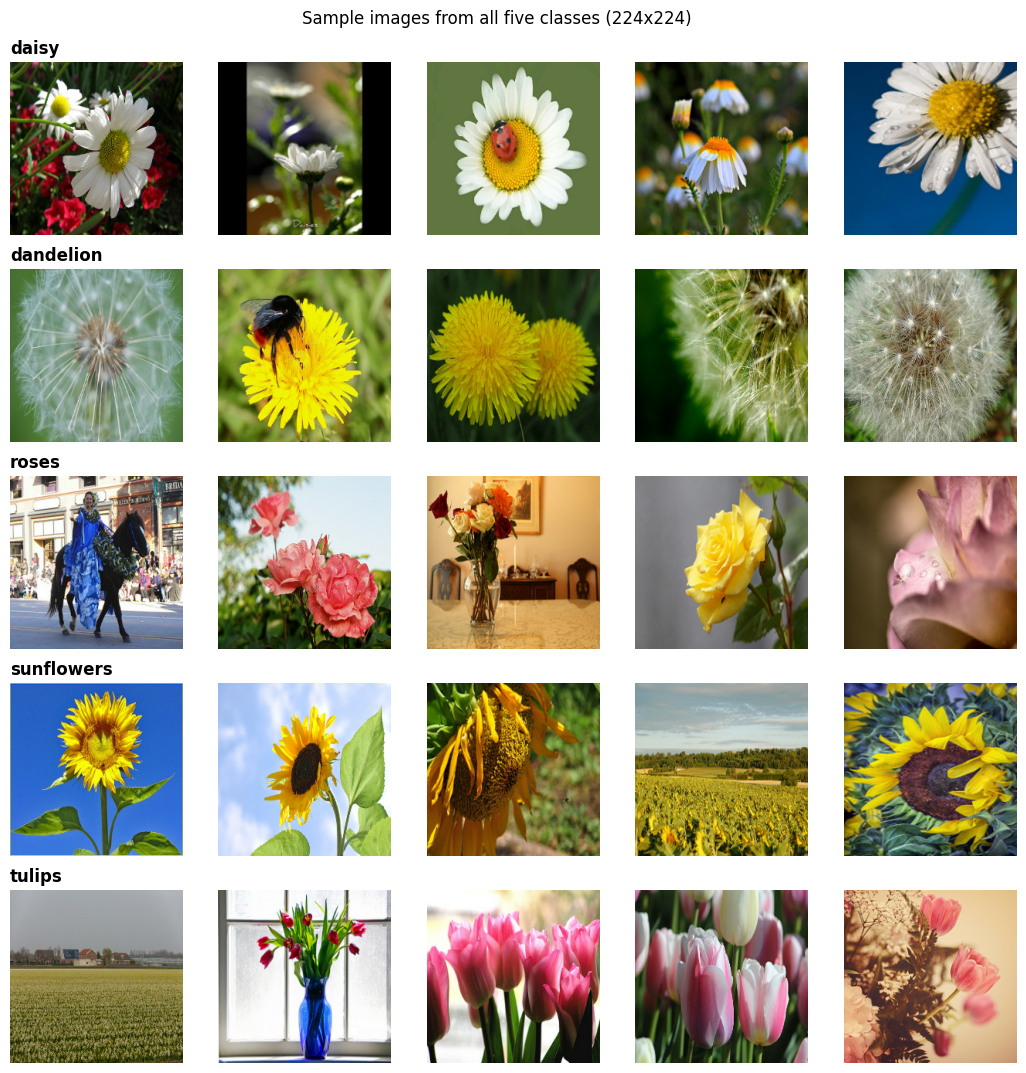

In [3]:
data_dir = pathlib.Path(keras.utils.get_file(
    "flower_photos",
    "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz",
    untar=True))
if not (data_dir / "daisy").exists():
    data_dir = data_dir / "flower_photos"

CLASS_NAMES = sorted(p.name for p in data_dir.iterdir() if p.is_dir())
print("Classes:", CLASS_NAMES)

paths, labels = [], []
for i, c in enumerate(CLASS_NAMES):
    for f in sorted((data_dir / c).glob("*.jpg")):
        paths.append(str(f)); labels.append(i)
paths, labels = np.array(paths), np.array(labels)

# same split (seed 42) in every notebook -> identical train / validation / test images for all six models
p_tr, p_tmp, y_tr, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_va, p_te, y_va, y_te = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
y_test = y_te
print(f"Train {len(p_tr)} | Val {len(p_va)} | Test {len(p_te)}")
for nm, y in [("train", y_tr), ("val", y_va), ("test", y_te)]:
    print(nm, dict(zip(CLASS_NAMES, np.bincount(y, minlength=NUM_CLASSES))))

def load_img(path):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    return tf.cast(tf.round(tf.image.resize(img, (IMG, IMG))), tf.uint8)

# Required visualization: sample images from all five classes
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(13, 13))
for c in range(NUM_CLASSES):
    for j, i in enumerate(np.where(y_tr == c)[0][:5]):
        axes[c, j].imshow(load_img(p_tr[i]).numpy()); axes[c, j].axis("off")
    axes[c, 0].set_title(CLASS_NAMES[c], loc="left", fontsize=12, fontweight="bold")
plt.suptitle("Sample images from all five classes (224x224)", y=0.92); plt.show()

## Task 3 – Preprocessing and augmentation pipeline (same for all models)

In [4]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05, fill_mode="reflect"),
    layers.RandomZoom(0.10, fill_mode="reflect"),
    layers.RandomTranslation(0.10, 0.10, fill_mode="reflect"),
    layers.RandomContrast(0.15),
], name="augmentation")

def prep(x):
    """ResNet50 / ImageNet preprocessing (input: 0-255 RGB)."""
    return keras.applications.resnet50.preprocess_input(tf.cast(x, tf.float32))

def make_base(p, y):
    ds = tf.data.Dataset.from_tensor_slices((p, y)).map(lambda a, b: (load_img(a), b), AUTOTUNE)
    return ds.cache()

train_base, val_base, test_base = make_base(p_tr, y_tr), make_base(p_va, y_va), make_base(p_te, y_te)

def make_train_ds():
    return (train_base.shuffle(1024, seed=SEED).batch(BATCH)
            .map(lambda x, y: (prep(augment(tf.cast(x, tf.float32), training=True)), tf.one_hot(y, NUM_CLASSES)), AUTOTUNE)
            .prefetch(AUTOTUNE))

def make_eval_ds(base):
    return base.batch(BATCH).map(lambda x, y: (prep(x), tf.one_hot(y, NUM_CLASSES)), AUTOTUNE).prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_train_ds(), make_eval_ds(val_base), make_eval_ds(test_base)

# test images as a small uint8 array (used for visualisation and timing only)
X_test = np.stack([x for x, _ in test_base.as_numpy_iterator()])
print("X_test:", X_test.shape, X_test.dtype)

X_test: (551, 224, 224, 3) uint8


## Task 4 – Attention modules (shape-preserving: H×W×C in → H×W×C out; `.maps()` exposes the internal weights)

In [5]:
class ChannelAttention(layers.Layer):
    """Mc(F) = sigmoid(W2 relu(W1 GAP(F))),  F_c = F * Mc(F)."""
    def __init__(self, ratio=REDUCTION, **kw):
        super().__init__(**kw); self.ratio = ratio
    def build(self, input_shape):
        C = int(input_shape[-1]); r = max(C // self.ratio, 1)
        self.fc1 = layers.Dense(r, activation="relu"); self.fc2 = layers.Dense(C, activation="sigmoid")
        self.fc1.build((None, C)); self.fc2.build((None, r)); super().build(input_shape)
    def _forward(self, x, training=None):
        m = self.fc2(self.fc1(tf.reduce_mean(x, axis=[1, 2])))
        return x * m[:, None, None, :], {"channel": m}
    def call(self, x, training=None): return self._forward(x)[0]
    def maps(self, x): return self._forward(x)[1]


class SpatialAttention(layers.Layer):
    """Ms(F) = sigmoid(Conv_kxk([mean_c(F); max_c(F)])),  F_s = F * Ms(F)."""
    def __init__(self, kernel_size=7, **kw):
        super().__init__(**kw); self.kernel_size = kernel_size
    def build(self, input_shape):
        self.conv = layers.Conv2D(1, self.kernel_size, padding="same", activation="sigmoid")
        self.conv.build((None, input_shape[1], input_shape[2], 2)); super().build(input_shape)
    def _forward(self, x, training=None):
        m = self.conv(tf.concat([tf.reduce_mean(x, axis=-1, keepdims=True), tf.reduce_max(x, axis=-1, keepdims=True)], axis=-1))
        return x * m, {"spatial": m}
    def call(self, x, training=None): return self._forward(x)[0]
    def maps(self, x): return self._forward(x)[1]


class ChannelSpatialAttention(layers.Layer):
    """order='cs': Channel -> Spatial ;  order='sc': Spatial -> Channel."""
    def __init__(self, order="cs", kernel_size=7, ratio=REDUCTION, **kw):
        super().__init__(**kw); self.order, self.kernel_size, self.ratio = order, kernel_size, ratio
    def build(self, input_shape):
        self.ca = ChannelAttention(self.ratio); self.sa = SpatialAttention(self.kernel_size)
        self.ca.build(input_shape); self.sa.build(input_shape); super().build(input_shape)
    def _forward(self, x, training=None):
        if self.order == "cs":
            xc, mc = self.ca._forward(x); out, ms = self.sa._forward(xc)
        else:
            xs, ms = self.sa._forward(x); out, mc = self.ca._forward(xs)
        return out, {**mc, **ms}
    def call(self, x, training=None): return self._forward(x)[0]
    def maps(self, x): return self._forward(x)[1]


class SelfAttention(layers.Layer):
    """Q=XWq, K=XWk, V=XWv, A=softmax(QK^T/sqrt(d)), F_SA = F + gamma * reshape(AV)."""
    def __init__(self, key_ratio=8, **kw):
        super().__init__(**kw); self.key_ratio = key_ratio
    def build(self, input_shape):
        self.H, self.W, self.C = int(input_shape[1]), int(input_shape[2]), int(input_shape[3])
        self.d = max(self.C // self.key_ratio, 1)
        self.q, self.k, self.v = layers.Dense(self.d), layers.Dense(self.d), layers.Dense(self.C)
        for l in (self.q, self.k, self.v): l.build((None, self.C))
        self.gamma = self.add_weight(shape=(1,), initializer="zeros", trainable=True, name="gamma")
        super().build(input_shape)
    def _forward(self, x, training=None):
        B = tf.shape(x)[0]; N = self.H * self.W
        X = tf.reshape(x, (B, N, self.C))
        A = tf.nn.softmax(tf.matmul(self.q(X), self.k(X), transpose_b=True) / math.sqrt(self.d), axis=-1)
        Y = tf.reshape(tf.matmul(A, self.v(X)), (B, self.H, self.W, self.C))
        return x + self.gamma * Y, {"attn": A}
    def call(self, x, training=None): return self._forward(x)[0]
    def maps(self, x): return self._forward(x)[1]


class CombinedAttention(layers.Layer):
    """Channel -> Spatial -> Self-attention."""
    def __init__(self, kernel_size=7, ratio=REDUCTION, **kw):
        super().__init__(**kw); self.kernel_size, self.ratio = kernel_size, ratio
    def build(self, input_shape):
        self.ca = ChannelAttention(self.ratio); self.sa = SpatialAttention(self.kernel_size); self.sf = SelfAttention()
        for l in (self.ca, self.sa, self.sf): l.build(input_shape)
        super().build(input_shape)
    def _forward(self, x, training=None):
        x, mc = self.ca._forward(x); x, ms = self.sa._forward(x); x, mf = self.sf._forward(x)
        return x, {**mc, **ms, **mf}
    def call(self, x, training=None): return self._forward(x)[0]
    def maps(self, x): return self._forward(x)[1]

ATT = {"channel": ChannelAttention, "spatial": SpatialAttention, "cs": ChannelSpatialAttention,
       "self": SelfAttention, "combined": CombinedAttention}
print("Attention modules defined.")

Attention modules defined.


## Task 5 – ResNet50 with the attention module for this model
The network is rebuilt with the **same layer names as `keras.applications.ResNet50`** so the ImageNet weights can be copied across and the module can be inserted between stages (`conv4_x → attention → conv5_x`, position P3).
The cell checks that the rebuilt backbone reproduces the original pretrained network, and prints the feature dimensions before and after the attention block.

In [6]:
STAGES = [("conv2", 64, 3, 1), ("conv3", 128, 4, 2), ("conv4", 256, 6, 2), ("conv5", 512, 3, 2)]
STAGE_OUT = {"P1": "conv2_block3_out", "P2": "conv3_block4_out", "P3": "conv4_block6_out", "P4": "conv5_block3_out"}
ATTN_CFG = {"P3": ("cs", dict(order="cs", kernel_size=7))}          # {} for the baseline

def res_block(x, filters, stride=1, conv_shortcut=True, name=None):
    if conv_shortcut:
        sc = layers.Conv2D(4 * filters, 1, strides=stride, name=name + "_0_conv")(x)
        sc = layers.BatchNormalization(axis=3, epsilon=1.001e-5, name=name + "_0_bn")(sc)
    else:
        sc = x
    x = layers.Conv2D(filters, 1, strides=stride, name=name + "_1_conv")(x)
    x = layers.BatchNormalization(axis=3, epsilon=1.001e-5, name=name + "_1_bn")(x)
    x = layers.Activation("relu", name=name + "_1_relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", name=name + "_2_conv")(x)
    x = layers.BatchNormalization(axis=3, epsilon=1.001e-5, name=name + "_2_bn")(x)
    x = layers.Activation("relu", name=name + "_2_relu")(x)
    x = layers.Conv2D(4 * filters, 1, name=name + "_3_conv")(x)
    x = layers.BatchNormalization(axis=3, epsilon=1.001e-5, name=name + "_3_bn")(x)
    x = layers.Add(name=name + "_add")([sc, x])
    return layers.Activation("relu", name=name + "_out")(x)

def build_model(attn_cfg, dropout=DROPOUT, name="resnet50_attention"):
    inp = layers.Input((IMG, IMG, 3), name="input_image")
    x = layers.ZeroPadding2D(3, name="conv1_pad")(inp)
    x = layers.Conv2D(64, 7, strides=2, name="conv1_conv")(x)
    x = layers.BatchNormalization(axis=3, epsilon=1.001e-5, name="conv1_bn")(x)
    x = layers.Activation("relu", name="conv1_relu")(x)
    x = layers.ZeroPadding2D(1, name="pool1_pad")(x)
    x = layers.MaxPooling2D(3, strides=2, name="pool1_pool")(x)
    for i, (sn, f, n, s) in enumerate(STAGES, start=1):
        x = res_block(x, f, stride=s, conv_shortcut=True, name=f"{sn}_block1")
        for b in range(2, n + 1):
            x = res_block(x, f, conv_shortcut=False, name=f"{sn}_block{b}")
        if f"P{i}" in attn_cfg:
            kind, kw = attn_cfg[f"P{i}"]
            x = ATT[kind](name=f"att_P{i}", **kw)(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="dropout")(x)
    return keras.Model(inp, layers.Dense(NUM_CLASSES, activation="softmax", name="classifier")(x), name=name)

base = keras.applications.ResNet50(weights="imagenet", include_top=False, input_shape=(IMG, IMG, 3))
BASE_NAMES = {l.name for l in base.layers}

def transfer_weights(model):
    n = 0
    for l in model.layers:
        if l.weights and l.name in BASE_NAMES:
            l.set_weights(base.get_layer(l.name).get_weights()); n += 1
    return n

model = build_model(ATTN_CFG, name=MODEL_KEY)
print("pretrained layers copied:", transfer_weights(model))

# sanity check: rebuilt backbone == keras.applications.ResNet50
xs = prep(X_test[:4]).numpy()
ref = base.predict(xs, verbose=0)
mine = keras.Model(model.input, model.get_layer("conv5_block3_out").output).predict(xs, verbose=0)
print("max |difference| vs keras.applications.ResNet50:", float(np.abs(ref - mine).max()))

# feature dimensions before / after the attention block
print("\nFeature dimensions at the candidate positions:")
for pos, ln in STAGE_OUT.items(): print(" ", pos, ln, tuple(model.get_layer(ln).output.shape))
for l in model.layers:
    if l.name.startswith("att_"):
        print(f"\n{l.name}: input {tuple(l.input.shape)} -> output {tuple(l.output.shape)}  (unchanged)")
if not ATTN_CFG: print("\nBaseline: no attention module.")
model.summary(print_fn=lambda s: None)
print("Total parameters:", f"{model.count_params():,}")
del base; gc.collect()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
pretrained layers copied: 106
max |difference| vs keras.applications.ResNet50: 50.2320671081543

Feature dimensions at the candidate positions:
  P1 conv2_block3_out (None, 56, 56, 256)
  P2 conv3_block4_out (None, 28, 28, 512)
  P3 conv4_block6_out (None, 14, 14, 1024)
  P4 conv5_block3_out (None, 7, 7, 2048)

att_P3: input (None, 14, 14, 1024) -> output (None, 14, 14, 1024)  (unchanged)


Total parameters: 23,730,216


54051

## Task 6 – Training
Two phases, identical for all six models: (1) backbone frozen → train the attention module and classifier (Adam 1e-3); (2) unfreeze `conv5_x` (BatchNorm stays frozen) and fine-tune (Adam 1e-4).
Loss: categorical cross-entropy. The weights of the best-validation epoch of phase 2 are used for testing.

In [7]:
def count(vs): return int(sum(np.prod(v.shape) for v in vs))

def set_phase(model, phase):
    for l in model.layers:
        pretrained = l.name in BASE_NAMES
        if phase == 1:
            l.trainable = not pretrained
        else:
            unfreeze = l.name.startswith("conv5_") and not isinstance(l, layers.BatchNormalization)
            l.trainable = (not pretrained) or unfreeze

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="categorical_crossentropy", metrics=["accuracy"])

WEIGHTS_PATH = f"{WORK}/{MODEL_KEY}.weights.h5"
t0 = time.time()

print(f"--- Phase 1: frozen backbone, {HEAD_EPOCHS} epochs ---")
set_phase(model, 1); compile_model(model, LR_HEAD)
trainable_p1 = count(model.trainable_weights)
h1 = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, verbose=2)

print(f"--- Phase 2: fine-tune conv5_x, {FT_EPOCHS} epochs ---")
set_phase(model, 2); compile_model(model, LR_FT)
trainable_ft = count(model.trainable_weights)
ckpt = keras.callbacks.ModelCheckpoint(WEIGHTS_PATH, monitor="val_accuracy", mode="max", save_best_only=True, save_weights_only=True)
h2 = model.fit(train_ds, validation_data=val_ds, epochs=FT_EPOCHS, callbacks=[ckpt], verbose=2)

train_time = time.time() - t0
model.load_weights(WEIGHTS_PATH)
history = {k: [float(v) for v in h1.history[k] + h2.history[k]] for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}
print(f"Training finished in {train_time/60:.1f} min | trainable params phase1 / phase2: {trainable_p1:,} / {trainable_ft:,}")

--- Phase 1: frozen backbone, 10 epochs ---
Epoch 1/10
81/81 - 71s - 871ms/step - accuracy: 0.6773 - loss: 0.7993 - val_accuracy: 0.8527 - val_loss: 0.4034
Epoch 2/10
81/81 - 36s - 441ms/step - accuracy: 0.8657 - loss: 0.3580 - val_accuracy: 0.8782 - val_loss: 0.3499
Epoch 3/10
81/81 - 37s - 461ms/step - accuracy: 0.8972 - loss: 0.2920 - val_accuracy: 0.8818 - val_loss: 0.3386
Epoch 4/10
81/81 - 36s - 447ms/step - accuracy: 0.9101 - loss: 0.2528 - val_accuracy: 0.8927 - val_loss: 0.3116
Epoch 5/10
81/81 - 37s - 458ms/step - accuracy: 0.9186 - loss: 0.2112 - val_accuracy: 0.8982 - val_loss: 0.3313
Epoch 6/10
81/81 - 41s - 503ms/step - accuracy: 0.9280 - loss: 0.2005 - val_accuracy: 0.9018 - val_loss: 0.2998
Epoch 7/10
81/81 - 36s - 448ms/step - accuracy: 0.9295 - loss: 0.2008 - val_accuracy: 0.9018 - val_loss: 0.3117
Epoch 8/10
81/81 - 37s - 455ms/step - accuracy: 0.9303 - loss: 0.1834 - val_accuracy: 0.8964 - val_loss: 0.3035
Epoch 9/10
81/81 - 38s - 472ms/step - accuracy: 0.9424 - los

## Task 7 – Evaluation: accuracy, precision, recall, macro-F1, parameters, inference time (saved for comparison)

In [8]:
probs = model.predict(test_ds, verbose=0); y_pred = probs.argmax(1)
acc = float(accuracy_score(y_test, y_pred))
prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
_, _, f1_per_class, _ = precision_recall_fscore_support(y_test, y_pred, average=None, zero_division=0)
tr_loss, tr_acc = model.evaluate(make_eval_ds(train_base), verbose=0)
va_loss, va_acc = model.evaluate(val_ds, verbose=0)

# inference time per image (ms): 160 test images, batch=BATCH, after warm-up, average of 3 passes
timing_batches = [prep(X_test[i:i + BATCH]) for i in range(0, min(160, len(X_test)), BATCH)]
n_timed = sum(int(b.shape[0]) for b in timing_batches)
_ = model(timing_batches[0], training=False).numpy()
ts = []
for _ in range(3):
    t = time.perf_counter()
    for b in timing_batches: _ = model(b, training=False).numpy()
    ts.append((time.perf_counter() - t) / n_timed * 1000)
infer_ms = float(np.mean(ts))

result = dict(key=MODEL_KEY, label=MODEL_LABEL, acc=acc, prec=float(prec), rec=float(rec), f1=float(f1),
              f1_per_class=[float(v) for v in f1_per_class], class_names=CLASS_NAMES,
              params_total=int(model.count_params()), params_trainable=trainable_ft, params_trainable_phase1=trainable_p1,
              infer_ms=infer_ms, train_acc=float(tr_acc), val_acc=float(va_acc), train_loss=float(tr_loss), val_loss=float(va_loss),
              train_time_min=train_time / 60, history=history, y_pred=[int(v) for v in y_pred], y_true=[int(v) for v in y_test],
              epochs=[HEAD_EPOCHS, FT_EPOCHS], seed=SEED)
for d in [WORK, DRIVE_DIR]:
    if d: json.dump(result, open(f"{d}/{MODEL_KEY}.json", "w"))

summary = pd.DataFrame([{"Model": MODEL_LABEL, "Test Accuracy": acc, "Precision (macro)": prec, "Recall (macro)": rec,
                         "Macro F1": f1, "Total Params": result["params_total"], "Trainable Params": trainable_ft,
                         "Inference (ms/img)": infer_ms, "Train Acc": tr_acc, "Val Acc": va_acc,
                         "Train Loss": tr_loss, "Val Loss": va_loss}]).round(4)
display(summary.T.rename(columns={0: MODEL_KEY}))
print("Results saved to", WORK + (" and " + DRIVE_DIR if DRIVE_DIR else ""))
try:                                   # download the results file to your computer (works in Colab only)
    from google.colab import files
    files.download(f"{WORK}/{MODEL_KEY}.json")
except Exception:
    pass

,A3
Model,Channel + Spatial Attention
Test Accuracy,0.9383
Precision (macro),0.9411
Recall (macro),0.9379
Macro F1,0.9381
Total Params,23730216
Trainable Params,15095976
Inference (ms/img),7.319
Train Acc,0.9879
Val Acc,0.9273


Results saved to /content/lab89


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Task 8 – Training / validation accuracy and loss vs epoch

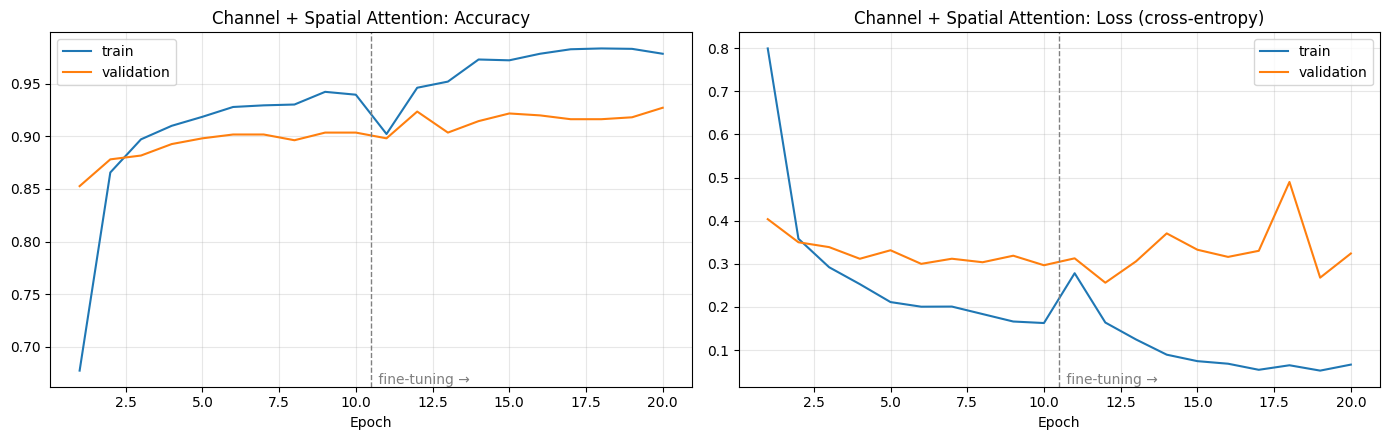

final train acc 0.9786 | final val acc 0.9273 | gap +0.0513 | best val acc 0.9273 (epoch 20)


In [9]:
ep = np.arange(1, len(history["accuracy"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (a, b), ttl in [(axes[0], ("accuracy", "val_accuracy"), "Accuracy"), (axes[1], ("loss", "val_loss"), "Loss (cross-entropy)")]:
    ax.plot(ep, history[a], label="train"); ax.plot(ep, history[b], label="validation")
    ax.axvline(HEAD_EPOCHS + 0.5, color="gray", ls="--", lw=1); ax.text(HEAD_EPOCHS + 0.6, ax.get_ylim()[0], " fine-tuning →", color="gray", va="bottom")
    ax.set_title(f"{MODEL_LABEL}: {ttl}"); ax.set_xlabel("Epoch"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()
print(f"final train acc {history['accuracy'][-1]:.4f} | final val acc {history['val_accuracy'][-1]:.4f} | "
      f"gap {history['accuracy'][-1]-history['val_accuracy'][-1]:+.4f} | best val acc {max(history['val_accuracy']):.4f} "
      f"(epoch {int(np.argmax(history['val_accuracy']))+1})")

## Task 9 – Confusion matrix and per-class results

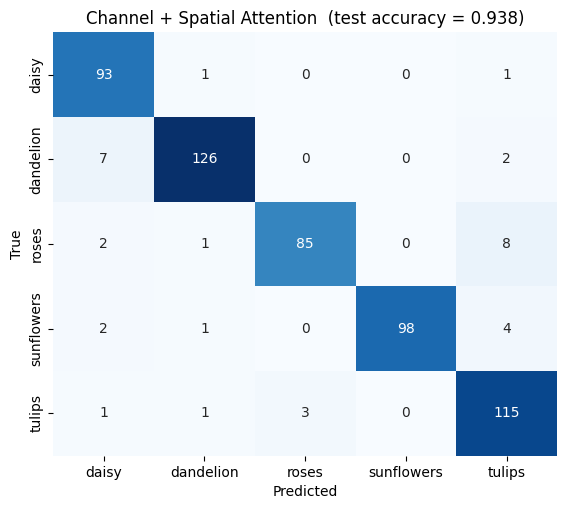

Most frequent confusions (count, true, predicted): [(8, 'roses', 'tulips'), (7, 'dandelion', 'daisy'), (4, 'sunflowers', 'tulips')]
              precision    recall  f1-score   support

       daisy      0.886     0.979     0.930        95
   dandelion      0.969     0.933     0.951       135
       roses      0.966     0.885     0.924        96
  sunflowers      1.000     0.933     0.966       105
      tulips      0.885     0.958     0.920       120

    accuracy                          0.938       551
   macro avg      0.941     0.938     0.938       551
weighted avg      0.942     0.938     0.939       551



In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
plt.title(f"{MODEL_LABEL}  (test accuracy = {acc:.3f})"); plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(int(off[i, j]), CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if off[i, j] > 0], reverse=True)[:3]
print("Most frequent confusions (count, true, predicted):", pairs)
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

## Task 10 – Attention visualisation
For one test image per class: the input, the mean feature map **before** and **after** the attention block at P3, and every attention map this module produces
(channel-attention top-10 weights, spatial-attention overlay, self-attention response – whichever apply to this model).

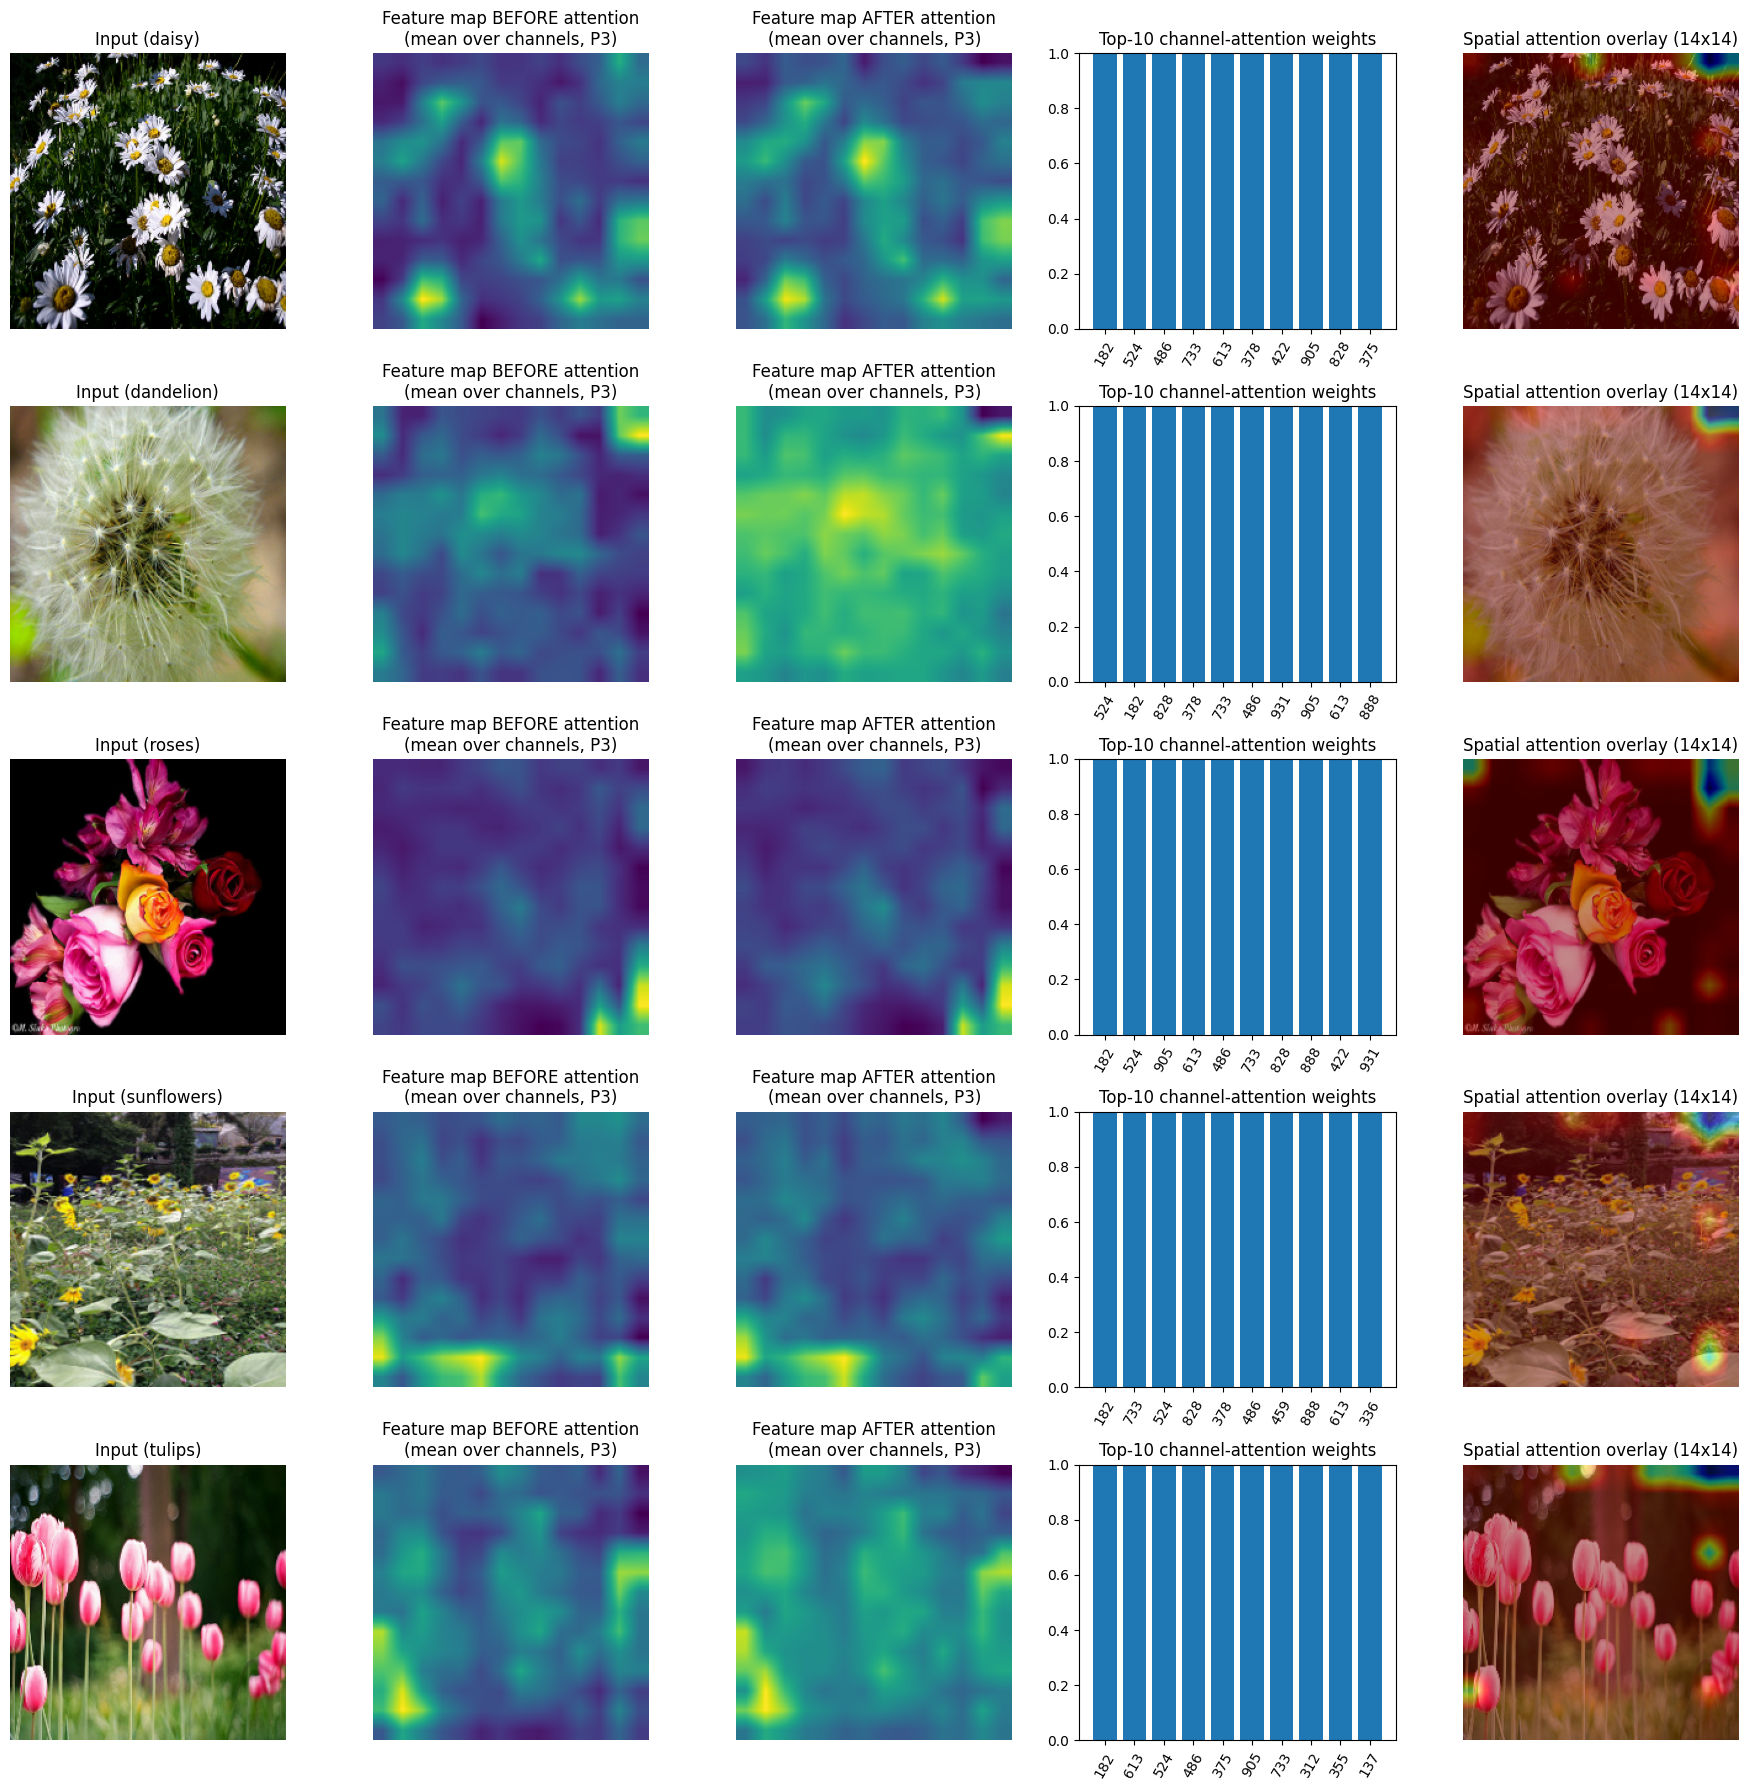

Channel weights (20 test images): mean 0.599 | std across channels 0.427 | share of weights > 0.7: 0.571


In [11]:
def one(i): return prep(X_test[i:i + 1]).numpy()
def resize_map(m): return tf.image.resize(np.asarray(m, dtype=np.float32)[..., None], (IMG, IMG)).numpy()[..., 0]
def norm01(m): m = np.asarray(m, dtype=np.float32); return (m - m.min()) / (m.max() - m.min() + 1e-8)
def overlay(img, heat, alpha=0.45):
    return np.clip((1 - alpha) * img / 255.0 + alpha * plt.get_cmap("jet")(norm01(heat))[..., :3], 0, 1)

feat_model = keras.Model(model.input, model.get_layer(STAGE_OUT["P3"]).output)
att_layer = model.get_layer("att_P3")
IDS = [int(np.where(y_test == c)[0][0]) for c in range(NUM_CLASSES)]      # first test image of every class

rows = []
for idx in IDS:
    before = feat_model(one(idx), training=False)
    after = att_layer(before, training=False)
    rows.append((idx, before.numpy()[0], after.numpy()[0], {k: v.numpy()[0] for k, v in att_layer.maps(before).items()}))

kinds = [k for k in ["channel", "spatial", "attn"] if k in rows[0][3]]
ncol = 3 + len(kinds) + (1 if "attn" in kinds else 0)
fig, axes = plt.subplots(len(rows), ncol, figsize=(3.6 * ncol, 3.6 * len(rows)))
for r, (idx, bf, af, mp) in enumerate(rows):
    c = 0
    axes[r, c].imshow(X_test[idx]); axes[r, c].set_title(f"Input ({CLASS_NAMES[y_test[idx]]})"); c += 1
    axes[r, c].imshow(resize_map(bf.mean(-1)), cmap="viridis"); axes[r, c].set_title("Feature map BEFORE attention\n(mean over channels, P3)"); c += 1
    axes[r, c].imshow(resize_map(af.mean(-1)), cmap="viridis"); axes[r, c].set_title("Feature map AFTER attention\n(mean over channels, P3)"); c += 1
    if "channel" in kinds:
        w = mp["channel"]; top = np.argsort(w)[::-1][:10]
        axes[r, c].bar(range(10), w[top]); axes[r, c].set_xticks(range(10)); axes[r, c].set_xticklabels(top, rotation=60)
        axes[r, c].set_ylim(0, 1); axes[r, c].set_title("Top-10 channel-attention weights"); c += 1
    if "spatial" in kinds:
        axes[r, c].imshow(overlay(X_test[idx], resize_map(mp["spatial"][..., 0]))); axes[r, c].set_title("Spatial attention overlay (14x14)"); c += 1
    if "attn" in kinds:
        A = mp["attn"]; H = W = int(np.sqrt(A.shape[0])); q = (H // 2) * W + W // 2
        axes[r, c].imshow(overlay(X_test[idx], resize_map(A.mean(0).reshape(H, W)))); axes[r, c].set_title("Self-attention: mean over queries"); c += 1
        axes[r, c].imshow(overlay(X_test[idx], resize_map(A[q].reshape(H, W)))); axes[r, c].set_title("Self-attention: query at centre"); c += 1
    for a in axes[r]:
        if not a.has_data() or a.images: a.axis("off")
plt.tight_layout(); plt.show()

# short numerical summaries for the written comments
if "channel" in kinds:
    W_ch = np.stack([att_layer.maps(feat_model(one(i), training=False))["channel"].numpy()[0] for i in range(min(20, len(X_test)))])
    print("Channel weights (20 test images): mean %.3f | std across channels %.3f | share of weights > 0.7: %.3f"
          % (W_ch.mean(), W_ch.mean(0).std(), (W_ch > 0.7).mean()))
if hasattr(att_layer, "gamma"): print("Learned self-attention gamma:", float(att_layer.gamma.numpy()[0]))
if hasattr(att_layer, "sf"): print("Learned self-attention gamma:", float(att_layer.sf.gamma.numpy()[0]))

## Task 11 – Grad-CAM (last convolutional stage) on correctly and incorrectly classified test images

Grad-CAM images (first 3 correct, rest misclassified): [0, 1, 3, 17, 22]


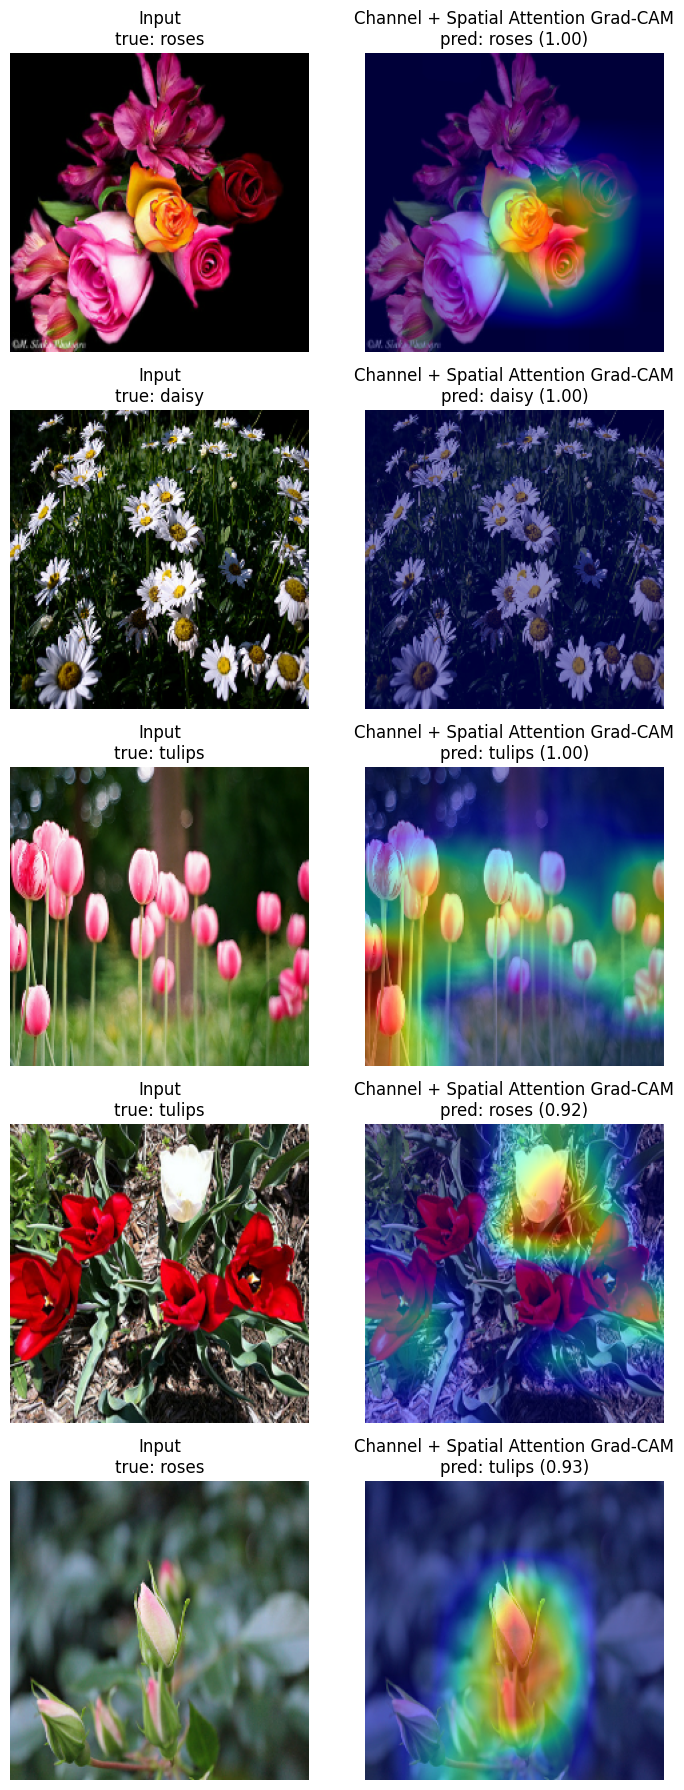

Mean Grad-CAM compactness over test images: 0.588


In [12]:
def one_img(i): return prep(X_test[i:i + 1]).numpy()
def _resize(m): return tf.image.resize(np.asarray(m, dtype=np.float32)[..., None], (IMG, IMG)).numpy()[..., 0]
def _norm(m): m = np.asarray(m, dtype=np.float32); return (m - m.min()) / (m.max() - m.min() + 1e-8)
def _overlay(img, heat, alpha=0.45):
    return np.clip((1 - alpha) * img / 255.0 + alpha * plt.get_cmap("jet")(_norm(heat))[..., :3], 0, 1)

def gradcam(model, x, layer_name="conv5_block3_out", class_idx=None):
    """Grad-CAM; class score = softmax probability of the predicted (or given) class."""
    gm = keras.Model(model.input, [model.get_layer(layer_name).output, model.output])
    x = tf.constant(x)
    with tf.GradientTape() as tape:
        conv, pred = gm(x, training=False)
        if class_idx is None: class_idx = int(tf.argmax(pred[0]))
        score = pred[:, class_idx]
    grads = tape.gradient(score, conv)
    alpha = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * alpha[:, None, None, :], axis=-1))[0].numpy()
    return cam / (cam.max() + 1e-8), class_idx, pred.numpy()[0]

correct = np.where(y_pred == y_test)[0]; wrong = np.where(y_pred != y_test)[0]
ids, seen = [], set()
for i in correct:                                   # up to 3 correct images from different classes
    if y_test[i] not in seen: ids.append(int(i)); seen.add(y_test[i])
    if len(ids) == 3: break
ids += [int(i) for i in wrong[:2]]                  # up to 2 misclassified images
print("Grad-CAM images (first 3 correct, rest misclassified):", ids)

fig, axes = plt.subplots(len(ids), 2, figsize=(7.5, 3.6 * len(ids)), squeeze=False)
for r, idx in enumerate(ids):
    cam, ci, pr = gradcam(model, one_img(idx))
    axes[r, 0].imshow(X_test[idx]); axes[r, 0].set_title(f"Input\ntrue: {CLASS_NAMES[y_test[idx]]}")
    axes[r, 1].imshow(_overlay(X_test[idx], _resize(cam))); axes[r, 1].set_title(f"{MODEL_LABEL} Grad-CAM\npred: {CLASS_NAMES[ci]} ({pr[ci]:.2f})")
    for a in axes[r]: a.axis("off")
plt.tight_layout(); plt.show()

def compactness(cam):          # share of the total activation that sits in the top-20% of pixels (higher = more focused)
    c = np.sort(_resize(cam).ravel())[::-1]; return c[: len(c) // 5].sum() / (c.sum() + 1e-8)
comp = float(np.mean([compactness(gradcam(model, one_img(i))[0]) for i in range(min(30, len(X_test)))]))
result["gradcam_compactness"] = comp
for d in [WORK, DRIVE_DIR]:
    if d: json.dump(result, open(f"{d}/{MODEL_KEY}.json", "w"))
print(f"Mean Grad-CAM compactness over test images: {comp:.3f}")

## Task 12 – Final summary of this model
Copy these numbers into the comparison table. The `.json` file saved in Task 7 contains everything needed to compare all six models later.

In [13]:
print(f"Model                 : {MODEL_LABEL}")
print(f"Test accuracy         : {acc:.4f}")
print(f"Precision / Recall    : {prec:.4f} / {rec:.4f}")
print(f"Macro F1              : {f1:.4f}")
print(f"Per-class F1          : " + ", ".join(f"{n} {v:.3f}" for n, v in zip(CLASS_NAMES, f1_per_class)))
print(f"Total params          : {result['params_total']:,}")
print(f"Trainable params (FT) : {trainable_ft:,}")
print(f"Inference time        : {infer_ms:.2f} ms / image")
print(f"Train / Val accuracy  : {tr_acc:.4f} / {va_acc:.4f}")
print(f"Training time         : {train_time/60:.1f} min")

Model                 : Channel + Spatial Attention
Test accuracy         : 0.9383
Precision / Recall    : 0.9411 / 0.9379
Macro F1              : 0.9381
Per-class F1          : daisy 0.930, dandelion 0.951, roses 0.924, sunflowers 0.966, tulips 0.920
Total params          : 23,730,216
Trainable params (FT) : 15,095,976
Inference time        : 7.32 ms / image
Train / Val accuracy  : 0.9879 / 0.9273
Training time         : 13.8 min
